# Q2: ผู้ใช้บริการต้นปี 2569 เทียบช่วงเดียวกันของปี 2568
**กลุ่ม:** Loading Brain... 1%

**คำถาม:** ปริมาณผู้ใช้บริการช่วงต้นปี พ.ศ. 2569 เปลี่ยนแปลงจากช่วงเดียวกันของปี พ.ศ. 2568 อย่างไร และการจัดการค่าว่าง/ค่าศูนย์ต่างวิธีส่งผลต่ออันดับหรือข้อสรุปอย่างไร

**ขอบเขต**
- ช่วงวันที่ 1 ม.ค.–11 มี.ค. ทั้งสองปี (ปี 2569 มีข้อมูลถึง 11 มี.ค.) ปีละ 70 วัน มีวันธรรมดา 50 และวันหยุด 20 วันเท่ากัน
- หน่วยคนเท่านั้น และตัด 3 บริการที่ไม่มีข้อมูลในปีใดปีหนึ่ง เหลือ 36 บริการ (ชุดเดียวกับ Q1)
- เทียบด้วยค่าเฉลี่ยต่อวัน เพราะบางบริการขาดข้อมูลไม่เท่ากันในแต่ละปี

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
plt.rcParams["font.family"] = "Tahoma" # แสดงภาษาไทยในกราฟ

# โหลดข้อมูลที่เตรียมแล้วจาก 01 และแปลงวันที่กลับเป็น datetime
df = pd.read_csv("../outputs/prepared_daily.csv")
df["date"] = pd.to_datetime(df["date"], format= "%Y-%m-%d")
print("ขนาด: ", df.shape)

from pathlib import Path

# โฟลเดอร์เก็บรูป (สร้างให้ถ้ายังไม่มี)
FIG_DIR = Path("../outputs/figures")
FIG_DIR.mkdir(parents= True, exist_ok= True)

ขนาด:  (18705, 18)


## เตรียมข้อมูล Q2: ช่วงวันที่และบริการที่เทียบได้

In [2]:
# ตรวจว่าช่วงวันที่เทียบกันได้
# ช่วง 1 ม.ค.–11 มี.ค. ของทั้งสองปี (สร้างไว้แล้วใน 01 ขั้นที่ 4)
win = df[df["in_q2_window"] == 1]

# จำนวนวันธรรมดา (0) และวันหยุด (1) ต้องเท่ากันทั้งสองปี
display(win.groupby(["year", "is_weekend"])["date"].nunique())

year  is_weekend
2025  0             50
      1             20
2026  0             50
      1             20
Name: date, dtype: int64

In [3]:
# ตรวจความครบของแต่ละบริการ
# นับวันที่มีข้อมูลของแต่ละบริการในแต่ละปี (เต็ม = 70 วัน)
check = win.groupby(["ยานพาหนะ/ท่า", "หน่วย", "year"], as_index= False).agg(days= ("qty", "count"))
check["missing"] = 70 - check["days"]

# แสดงเฉพาะบริการที่ขาดข้อมูล
bad = check[check["missing"] > 0]
display(bad)

,ยานพาหนะ/ท่า,หน่วย,year,days,missing
32,รถ บขส. ขาออกประเทศ,คน,2025,68,2
33,รถ บขส. ขาออกประเทศ,คน,2026,67,3
34,รถ บขส. ขาเข้าประเทศ,คน,2025,68,2
35,รถ บขส. ขาเข้าประเทศ,คน,2026,67,3
38,รถยนต์ทุกประเภท (10 จุดสำรวจ),คัน,2025,44,26
39,รถยนต์ทุกประเภท (10 จุดสำรวจ),คัน,2026,5,65
40,รถยนต์ทุกประเภท (ทางด่วน),คัน,2025,66,4
42,รถยนต์เฉพาะ 4 ล้อ (10 จุดสำรวจ),คัน,2025,44,26
43,รถยนต์เฉพาะ 4 ล้อ (10 จุดสำรวจ),คัน,2026,5,65
44,รถยนต์เฉพาะ 4 ล้อ (ทางด่วน),คัน,2025,66,4


In [4]:
# เลือกข้อมูล Q2
# หน่วยคน และตัด 3 บริการที่ไม่มีข้อมูลในปีใดปีหนึ่ง
exclude = ["รถร่วม (หมวด 1)", "รถหมวด 3", "รถหมวด 4"]
df_q2 = win[(win["หน่วย"] == "คน") & ~win["ยานพาหนะ/ท่า"].isin(exclude)].copy()

print("ขนาด: ", df_q2.shape, "| บริการ: ", df_q2["ยานพาหนะ/ท่า"].nunique())
print("ค่าว่าง: ", df_q2["qty"].isna().sum(), "| ค่าศูนย์ที่ยังยืนยันไม่ได้: ", df_q2["zero_unconfirmed"].sum())

order = ["การเดินทางภายในจังหวัด/กรุงเทพ", "การเดินทางระหว่างจังหวัด", "การเดินทางระหว่างประเทศ"]

ขนาด:  (5040, 18) | บริการ:  36
ค่าว่าง:  10 | ค่าศูนย์ที่ยังยืนยันไม่ได้:  2


## 2.1 อัตราการเปลี่ยนแปลงรายบริการและรายกลุ่ม

1. หาค่าเฉลี่ยต่อวันของแต่ละบริการ แยกปี
2. pct_change = (ปี 2569 − ปี 2568) ÷ ปี 2568 × 100 แล้วเรียงอันดับจากเพิ่มมากสุด
3. ยอดของกลุ่ม = ผลรวมค่าเฉลี่ยต่อวันของบริการในกลุ่ม

ตัวอย่างคิดมือ (ในเมือง): (2,551,206 − 2,671,794) ÷ 2,671,794 × 100 = −4.5%

In [5]:
# 1) ค่าเฉลี่ยต่อวันของแต่ละบริการ แยกปี
svc = df_q2.groupby(["วัตถุประสงค์", "ยานพาหนะ/ท่า", "year"], as_index= False).agg(avg_daily= ("qty", "mean"))

# 2) แยกปีแล้ว merge ให้อยู่แถวเดียวกัน
y68 = svc[svc["year"] == 2025][["วัตถุประสงค์", "ยานพาหนะ/ท่า", "avg_daily"]]
y69 = svc[svc["year"] == 2026][["วัตถุประสงค์", "ยานพาหนะ/ท่า", "avg_daily"]]
chg = pd.merge(y68, y69, on= ["วัตถุประสงค์", "ยานพาหนะ/ท่า"], how= "inner", validate= "one_to_one")
chg = chg.rename(columns= {"avg_daily_x": "avg_2568", "avg_daily_y": "avg_2569"})

# 3) อัตราการเปลี่ยนแปลง และอันดับ (1 = เพิ่มมากสุด)
chg["pct_change"] = (chg["avg_2569"] - chg["avg_2568"]) / chg["avg_2568"] * 100
chg = chg.sort_values("pct_change", ascending= False).reset_index(drop= True)
chg["rank"] = range(1, len(chg) + 1)
display(chg.round(1))

,วัตถุประสงค์,ยานพาหนะ/ท่า,avg_2568,avg_2569,pct_change,rank
0,การเดินทางระหว่างจังหวัด,ท่าอากาศยานอู่ตะเภา,201.3,290.9,44.5,1
1,การเดินทางระหว่างประเทศ,ท่าอากาศยานภูมิภาค ขาเข้าประเทศ,1168.5,1652.7,41.4,2
2,การเดินทางระหว่างประเทศ,ท่าอากาศยานภูมิภาค ขาออกประเทศ,1319.1,1842.4,39.7,3
3,การเดินทางระหว่างจังหวัด,ท่าอากาศยานภูมิภาค,19375.6,23039.5,18.9,4
4,การเดินทางภายในจังหวัด/กรุงเทพ,เรือไฟฟ้าเจ้าพระยา,3114.8,3647.5,17.1,5
5,การเดินทางระหว่างจังหวัด,ท่าอากาศยานดอนเมือง,28439.5,32389.3,13.9,6
6,การเดินทางภายในจังหวัด/กรุงเทพ,เรือภูมิภาค,198577.4,210239.8,5.9,7
7,การเดินทางระหว่างประเทศ,ท่าอากาศยานสุวรรณภูมิ ขาออกประเทศ,68263.2,72022.4,5.5,8
8,การเดินทางระหว่างจังหวัด,ท่าอากาศยานอื่น ๆ ของ ทอท.,27945.3,29458.1,5.4,9
9,การเดินทางระหว่างจังหวัด,ท่าอากาศยานสมุย,4310.3,4541.1,5.4,10


In [6]:
# รายกลุ่ม
# ยอดของกลุ่ม = ผลรวมค่าเฉลี่ยต่อวันของบริการในกลุ่ม
grp = chg.groupby("วัตถุประสงค์", as_index= False).agg(avg_2568= ("avg_2568","sum"), avg_2569= ("avg_2569", "sum"))
grp["pct_change"] = (grp["avg_2569"] - grp["avg_2568"]) / grp["avg_2568"] * 100
display(grp.round(1))

# รวมทั้ง 36 บริการ
total68 = grp["avg_2568"].sum()
total69 = grp["avg_2569"].sum()
print(f"รวม 36 บริการ: {round(total68)} -> {round(total69)} = {round((total69 - total68) / total68 *100, 1)} %")

,วัตถุประสงค์,avg_2568,avg_2569,pct_change
0,การเดินทางภายในจังหวัด/กรุงเทพ,2671794.5,2551205.9,-4.5
1,การเดินทางระหว่างจังหวัด,277971.2,279449.3,0.5
2,การเดินทางระหว่างประเทศ,244514.3,251840.3,3.0


รวม 36 บริการ: 3194280 -> 3082495 = -3.5 %


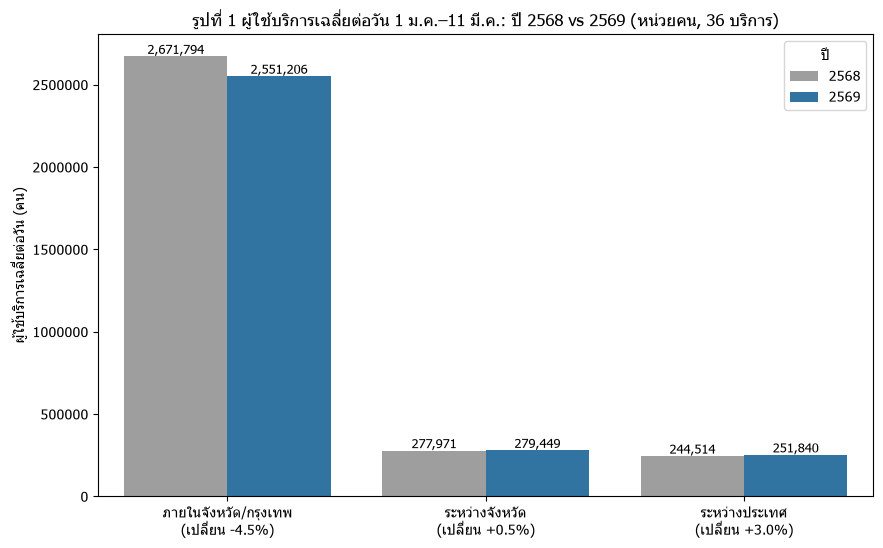

In [7]:
# จัดข้อมูลเป็นแบบยาว (ปีเป็นคอลัมน์เดียว) เพื่อใช้ hue
plot1 = pd.concat([
    pd.DataFrame({"วัตถุประสงค์": grp["วัตถุประสงค์"], "ปี": "2568", "avg_daily": grp["avg_2568"]}),
    pd.DataFrame({"วัตถุประสงค์": grp["วัตถุประสงค์"], "ปี": "2569", "avg_daily": grp["avg_2569"]})],
    ignore_index= True)

# ชื่อแกน x พร้อม % เปลี่ยน
labels = []
for p in order:
    v = grp.loc[grp["วัตถุประสงค์"] == p, "pct_change"].iloc[0]
    labels.append(p.replace("การเดินทาง", "") + f"\n(เปลี่ยน {v:+.1f}%)")

plt.figure(figsize= (10, 6))
ax = sns.barplot(data= plot1, x= "วัตถุประสงค์", y= "avg_daily", hue= "ปี", order= order,
                 palette= ["#9e9e9e", "C0"])                   # ปีก่อนสีเทา ปีนี้สีน้ำเงิน
for c in ax.containers:
    ax.bar_label(c, fmt= "{:,.0f}", fontsize= 9)
ax.set_xticks(range(3))
ax.set_xticklabels(labels)
plt.ticklabel_format(style= "plain", axis= "y")
plt.title("รูปที่ 1 ผู้ใช้บริการเฉลี่ยต่อวัน 1 ม.ค.–11 มี.ค.: ปี 2568 vs 2569 (หน่วยคน, 36 บริการ)")
plt.xlabel("")
plt.ylabel("ผู้ใช้บริการเฉลี่ยต่อวัน (คน)")
plt.legend(title= "ปี")
plt.savefig(FIG_DIR / "q2_fig1_group_yoy.png", dpi= 150, bbox_inches= "tight")   # บันทึกรูป
plt.show()

**วิธีอ่าน:** แท่งเทา = ปี 2568, แท่งน้ำเงิน = ปี 2569 วงเล็บใต้ชื่อกลุ่ม = เปลี่ยนไปกี่ %

**ผล:** ภาพรวม 36 บริการ **ลดลง 3.5%** (3,194,280 → 3,082,495 คน/วัน) แต่แต่ละกลุ่มไปคนละทาง
- **ในเมือง ลดลง 4.5%** (ประมาณ 120,000 คน/วัน) และเป็นกลุ่มเดียวที่ลด
- **ระหว่างจังหวัด เพิ่ม 0.5%** แทบไม่เปลี่ยน
- **ระหว่างประเทศ เพิ่ม 3.0%**

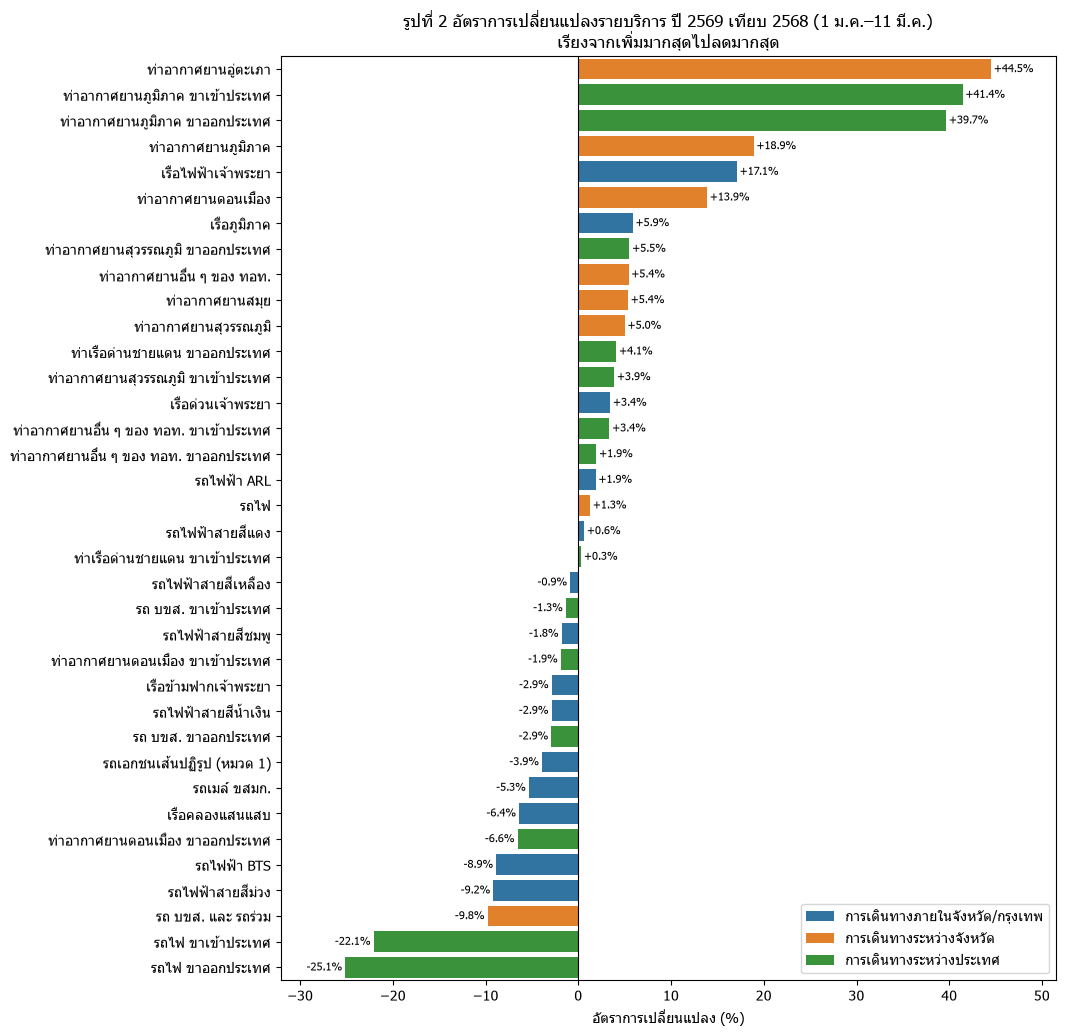

เพิ่มขึ้น: 20 บริการ | ลดลง: 16 บริการ


In [8]:
plt.figure(figsize= (10, 12))
ax = sns.barplot(data= chg, y= "ยานพาหนะ/ท่า", x= "pct_change", hue= "วัตถุประสงค์",
                 hue_order= order, dodge= False)
for c in ax.containers:
    ax.bar_label(c, fmt= "{:+.1f}%", fontsize= 8, padding= 2)
plt.axvline(0, color= "black", linewidth= 0.8)          # เส้น 0% = ไม่เปลี่ยน
plt.margins(x= 0.1)
plt.title("รูปที่ 2 อัตราการเปลี่ยนแปลงรายบริการ ปี 2569 เทียบ 2568 (1 ม.ค.–11 มี.ค.)\nเรียงจากเพิ่มมากสุดไปลดมากสุด")
plt.xlabel("อัตราการเปลี่ยนแปลง (%)")
plt.ylabel("")
plt.legend(title= "", loc= "lower right")
plt.savefig(FIG_DIR / "q2_fig2_service_pct_change.png", dpi= 150, bbox_inches= "tight")   # บันทึกรูป
plt.show()

print("เพิ่มขึ้น:", (chg["pct_change"] > 0).sum(), "บริการ | ลดลง:", (chg["pct_change"] < 0).sum(), "บริการ")

**ผล:** เพิ่มขึ้น 20 บริการ ลดลง 16 บริการ
- **เพิ่มมากสุด:** ท่าอากาศยานอู่ตะเภา +44.5%, ท่าอากาศยานภูมิภาค ขาเข้า/ขาออกประเทศ +41.4% / +39.7%
- **ลดมากสุด:** รถไฟ ขาออก/ขาเข้าประเทศ −25.1% / −22.1%, รถ บขส. และ รถร่วม −9.8%, รถไฟฟ้าสายสีม่วง −9.2%, BTS −8.9%
- กลุ่มในเมืองที่ลดลงมาจากบริการใหญ่ เช่น BTS (784,343 → 714,924 คน/วัน) และรถเมล์ ขสมก. (−5.3%)
- **ข้อควรระวัง:** % สูงสุด/ต่ำสุดมาจากบริการฐานเล็ก เช่น อู่ตะเภา (201 → 291 คน/วัน) และรถไฟระหว่างประเทศ (ประมาณ 360 คน/วัน) เปลี่ยนไม่กี่สิบคนก็ได้ % สูง จึงต้องดูคู่กับรูปที่ 1

## 2.2 ทดสอบการจัดการค่าว่างและค่าศูนย์ (Sensitivity Test)

ใช้บริการหน่วยคนทั้ง 39 รายการ (ยังไม่ตัด 3 บริการ) เพื่อดูว่าการตัดสินใจแต่ละแบบเปลี่ยนผลอย่างไร (AIE315 Lab 2 หัวข้อ 5, AIE314 บทที่ 5 หน้า 21–28)

| วิธี | การจัดการ |
|---|---|
| A (หลัก) | ข้ามค่าว่าง (Pairwise deletion) เก็บ 0 ไว้ |
| B | 0 ที่ยังยืนยันไม่ได้ ถือเป็นค่าว่าง |
| C | เติมค่าว่างด้วย 0 |
| D | เติมค่าว่างด้วยมัธยฐานของบริการในปีนั้น |

บริการที่คำนวณ % ไม่ได้ (ปีฐานไม่มีข้อมูลหรือเป็น 0) จะถูกตัดออกอัตโนมัติ
*groupby().transform ไม่พบในเอกสารวิชา ใช้หามัธยฐานแยกตามบริการและปีในวิธี D*

In [9]:
# บริการหน่วยคนทั้งหมดในช่วงเทียบ (ยังไม่ตัด 3 บริการ)
base = win[win["หน่วย"] == "คน"].copy()
print("บริการหน่วยคนทั้งหมด: ", base["ยานพาหนะ/ท่า"].nunique())

def run_method(data, name):
    x = data.copy()
    if name == "B":      # 0 ที่ยังยืนยันไม่ได้ → ค่าว่าง
        x.loc[x["zero_unconfirmed"] == 1, "qty"] = np.nan
    if name == "C":      # เติมค่าว่างด้วย 0
        x["qty"] = x["qty"].fillna(0)
    if name == "D":      # เติมค่าว่างด้วยมัธยฐานของบริการในปีนั้น
        med = x.groupby(["ยานพาหนะ/ท่า", "year"])["qty"].transform("median")
        x["qty"] = x["qty"].fillna(med)

    # คำนวณแบบเดียวกับ Cell 5
    s = x.groupby(["วัตถุประสงค์", "ยานพาหนะ/ท่า", "year"], as_index= False).agg(avg_daily= ("qty", "mean"))
    a = s[s["year"] == 2025][["วัตถุประสงค์", "ยานพาหนะ/ท่า", "avg_daily"]]
    b = s[s["year"] == 2026][["วัตถุประสงค์", "ยานพาหนะ/ท่า", "avg_daily"]]
    r = pd.merge(a, b, on= ["วัตถุประสงค์", "ยานพาหนะ/ท่า"], how= "inner", validate= "one_to_one")
    r["pct_change"] = (r["avg_daily_y"] - r["avg_daily_x"]) / r["avg_daily_x"] * 100
    r = r.dropna(subset= ["pct_change"])                 # ตัดบริการที่คำนวณ % ไม่ได้
    r = r.sort_values("pct_change", ascending= False).reset_index(drop= True)
    r["rank"] = range(1, len(r) + 1)
    r["method"] = name
    return r

sens = pd.concat([run_method(base, m) for m in ["A", "B", "C", "D"]], ignore_index= True)
display(sens.groupby("method").size())

บริการหน่วยคนทั้งหมด:  39


method
A    36
B    36
C    38
D    36
dtype: int64

In [10]:
sg = sens.groupby(["method", "วัตถุประสงค์"], as_index= False).agg(
    avg_2568= ("avg_daily_x", "sum"), avg_2569= ("avg_daily_y", "sum"))
sg["pct_change"] = (sg["avg_2569"] - sg["avg_2568"]) / sg["avg_2568"] * 100
display(sg.round(2))

,method,วัตถุประสงค์,avg_2568,avg_2569,pct_change
0,A,การเดินทางภายในจังหวัด/กรุงเทพ,2671794.46,2551205.93,-4.51
1,A,การเดินทางระหว่างจังหวัด,277971.20,279449.26,0.53
2,A,การเดินทางระหว่างประเทศ,244514.33,251840.26,3.00
3,B,การเดินทางภายในจังหวัด/กรุงเทพ,2673861.47,2551205.93,-4.59
4,B,การเดินทางระหว่างจังหวัด,277971.20,279449.26,0.53
5,B,การเดินทางระหว่างประเทศ,244514.33,251840.26,3.00
6,C,การเดินทางภายในจังหวัด/กรุงเทพ,2672626.34,2551205.93,-4.54
7,C,การเดินทางระหว่างจังหวัด,282719.24,279449.26,-1.16
8,C,การเดินทางระหว่างประเทศ,244452.60,251749.91,2.99
9,D,การเดินทางภายในจังหวัด/กรุงเทพ,2671794.46,2551205.93,-4.51


In [11]:
# ตาราง บริการ × วิธี (ค่า = อันดับ และ % เปลี่ยน)
rank_tab = sens.pivot_table(index= "ยานพาหนะ/ท่า", columns= "method", values= "rank")
pct_tab = sens.pivot_table(index= "ยานพาหนะ/ท่า", columns= "method", values= "pct_change")

# แสดงเฉพาะบริการที่อันดับต่างจากวิธี A อย่างน้อย 1 วิธี
moved = rank_tab[(rank_tab["B"] != rank_tab["A"]) | (rank_tab["C"] != rank_tab["A"]) | (rank_tab["D"] != rank_tab["A"])]
display(moved.sort_values("A"))
display(pct_tab.loc[moved.index].round(2).sort_values("A"))

for m in ["B", "C", "D"]:
    both = rank_tab[["A", m]].dropna()
    n_move = (both["A"] != both[m]).sum()
    print("วิธี", m, "เทียบ A: อันดับเปลี่ยน", n_move, "บริการ | เลื่อนมากสุด", int((both["A"] - both[m]).abs().max()), "อันดับ")

method,A,B,C,D
ยานพาหนะ/ท่า,,,,
รถไฟฟ้า ARL,17.0,21.0,17.0,17.0
รถไฟ,18.0,17.0,18.0,18.0
รถไฟฟ้าสายสีแดง,19.0,18.0,19.0,19.0
ท่าเรือด่านชายแดน ขาเข้าประเทศ,20.0,19.0,20.0,20.0
รถไฟฟ้าสายสีเหลือง,21.0,20.0,21.0,21.0
รถ บขส. ขาเข้าประเทศ,22.0,22.0,24.0,22.0
รถไฟฟ้าสายสีชมพู,23.0,23.0,22.0,23.0
ท่าอากาศยานดอนเมือง ขาเข้าประเทศ,24.0,24.0,23.0,24.0
เรือข้ามฟากเจ้าพระยา,25.0,25.0,25.0,26.0


method,A,B,C,D
ยานพาหนะ/ท่า,,,,
รถเอกชนเส้นปฏิรูป (หมวด 1),-3.91,-3.91,-3.91,-3.91
รถ บขส. ขาออกประเทศ,-2.91,-2.91,-4.34,-2.81
รถไฟฟ้าสายสีน้ำเงิน,-2.89,-2.89,-2.89,-2.89
เรือข้ามฟากเจ้าพระยา,-2.86,-2.86,-2.86,-2.86
ท่าอากาศยานดอนเมือง ขาเข้าประเทศ,-1.89,-1.89,-1.89,-1.89
รถไฟฟ้าสายสีชมพู,-1.80,-1.80,-1.80,-1.80
รถ บขส. ขาเข้าประเทศ,-1.34,-1.34,-2.79,-1.27
รถไฟฟ้าสายสีเหลือง,-0.88,-0.88,-0.88,-0.88
ท่าเรือด่านชายแดน ขาเข้าประเทศ,0.31,0.31,0.31,0.31


วิธี B เทียบ A: อันดับเปลี่ยน 5 บริการ | เลื่อนมากสุด 4 อันดับ
วิธี C เทียบ A: อันดับเปลี่ยน 5 บริการ | เลื่อนมากสุด 2 อันดับ
วิธี D เทียบ A: อันดับเปลี่ยน 3 บริการ | เลื่อนมากสุด 2 อันดับ


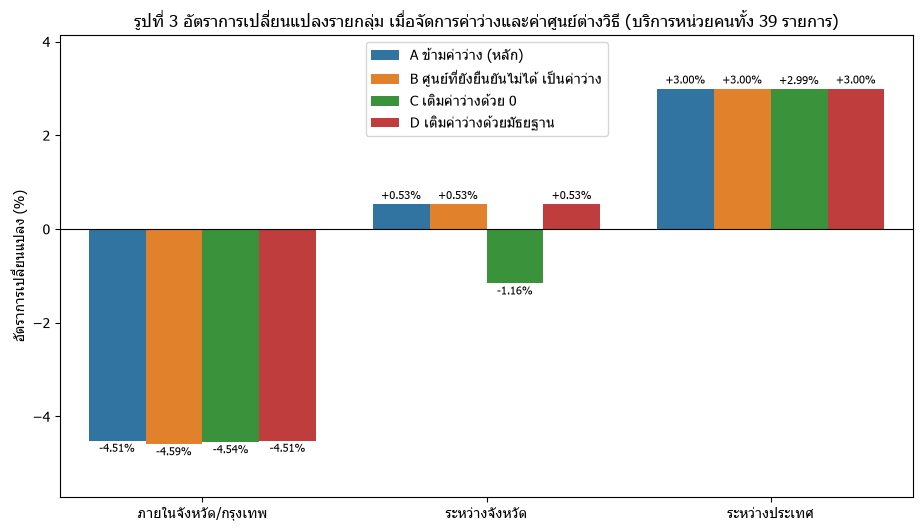

In [12]:
names = {"A": "A ข้ามค่าว่าง (หลัก)", "B": "B ศูนย์ที่ยังยืนยันไม่ได้ เป็นค่าว่าง",
         "C": "C เติมค่าว่างด้วย 0", "D": "D เติมค่าว่างด้วยมัธยฐาน"}
sg["วิธี"] = sg["method"].map(names)

plt.figure(figsize= (11, 6))
ax = sns.barplot(data= sg, x= "วัตถุประสงค์", y= "pct_change", hue= "วิธี", order= order)
for c in ax.containers:
    ax.bar_label(c, fmt= "{:+.2f}%", fontsize= 8, padding= 2)
plt.axhline(0, color= "black", linewidth= 0.8)
ax.set_xticks(range(3))
ax.set_xticklabels([p.replace("การเดินทาง", "") for p in order])
plt.margins(y= 0.15)
plt.title("รูปที่ 3 อัตราการเปลี่ยนแปลงรายกลุ่ม เมื่อจัดการค่าว่างและค่าศูนย์ต่างวิธี (บริการหน่วยคนทั้ง 39 รายการ)")
plt.xlabel("")
plt.ylabel("อัตราการเปลี่ยนแปลง (%)")
plt.legend(title= "", loc= "upper center")
plt.savefig(FIG_DIR / "q2_fig3_sensitivity.png", dpi= 150, bbox_inches= "tight")   # บันทึกรูป
plt.show()

**ผล:**

| กลุ่ม | A | B | C | D |
|---|---:|---:|---:|---:|
| ในเมือง | −4.51% | −4.59% | −4.54% | −4.51% |
| ระหว่างจังหวัด | +0.53% | +0.53% | **−1.16%** | +0.53% |
| ระหว่างประเทศ | +3.00% | +3.00% | +2.99% | +3.00% |

1. **วิธี C (เติม 0) เปลี่ยนข้อสรุป:** ระหว่างจังหวัดกลับจาก "เพิ่ม 0.53%" เป็น "ลด 1.16%" เพราะรถหมวด 3 ที่ไม่มีข้อมูลปี 2569 ถูกนับเป็น 0 คน (ปี 2568 เฉลี่ย 4,748 คน/วัน)
   คิดมือ: ปี 2568 = 277,971 + 4,748 = 282,719 → (279,449 − 282,719) ÷ 282,719 × 100 = −1.16%
   ค่าว่างแปลว่า "ไม่มีข้อมูล" ไม่ใช่ "ไม่มีผู้โดยสาร" จึงต้องตัดบริการที่ไม่มีข้อมูลในปีใดปีหนึ่งออกก่อนเทียบ
2. **วิธี B เปลี่ยนทิศทางของรถไฟฟ้า ARL:** ปี 2568 มีค่า 0 ที่ยังยืนยันไม่ได้ 2 วัน (16 ม.ค. และ 2 มี.ค. 2568)
   - A: 4,919,485 ÷ 70 = 70,278 คน/วัน → ปี 2569 71,593 = **+1.87%** (อันดับ 17)
   - B: 4,919,485 ÷ 68 = 72,345 คน/วัน → **−1.04%** (อันดับ 21)
   ดังนั้นข้อสรุปของ ARL "เพิ่มหรือลด" ยังสรุปไม่ได้จนกว่าจะยืนยันค่า 0 สองวันนี้
3. **วิธี D แทบไม่เปลี่ยนอะไร:** ค่าว่างใน 36 บริการมีแค่ 10 ค่า (รถ บขส. ระหว่างประเทศ) อันดับเลื่อนไม่เกิน 2 อันดับ
4. **ข้อสรุปหลักไม่เปลี่ยน** ในวิธี A, B, D: ในเมืองลด ประมาณ 4.5%, ระหว่างจังหวัดทรงตัว, ระหว่างประเทศเพิ่ม 3.0% และอันดับ 1–16 และ 29–36 เหมือนกันทุกวิธี อันดับที่เลื่อนอยู่ช่วงกลาง (17–28) ซึ่ง % ต่างกันน้อย

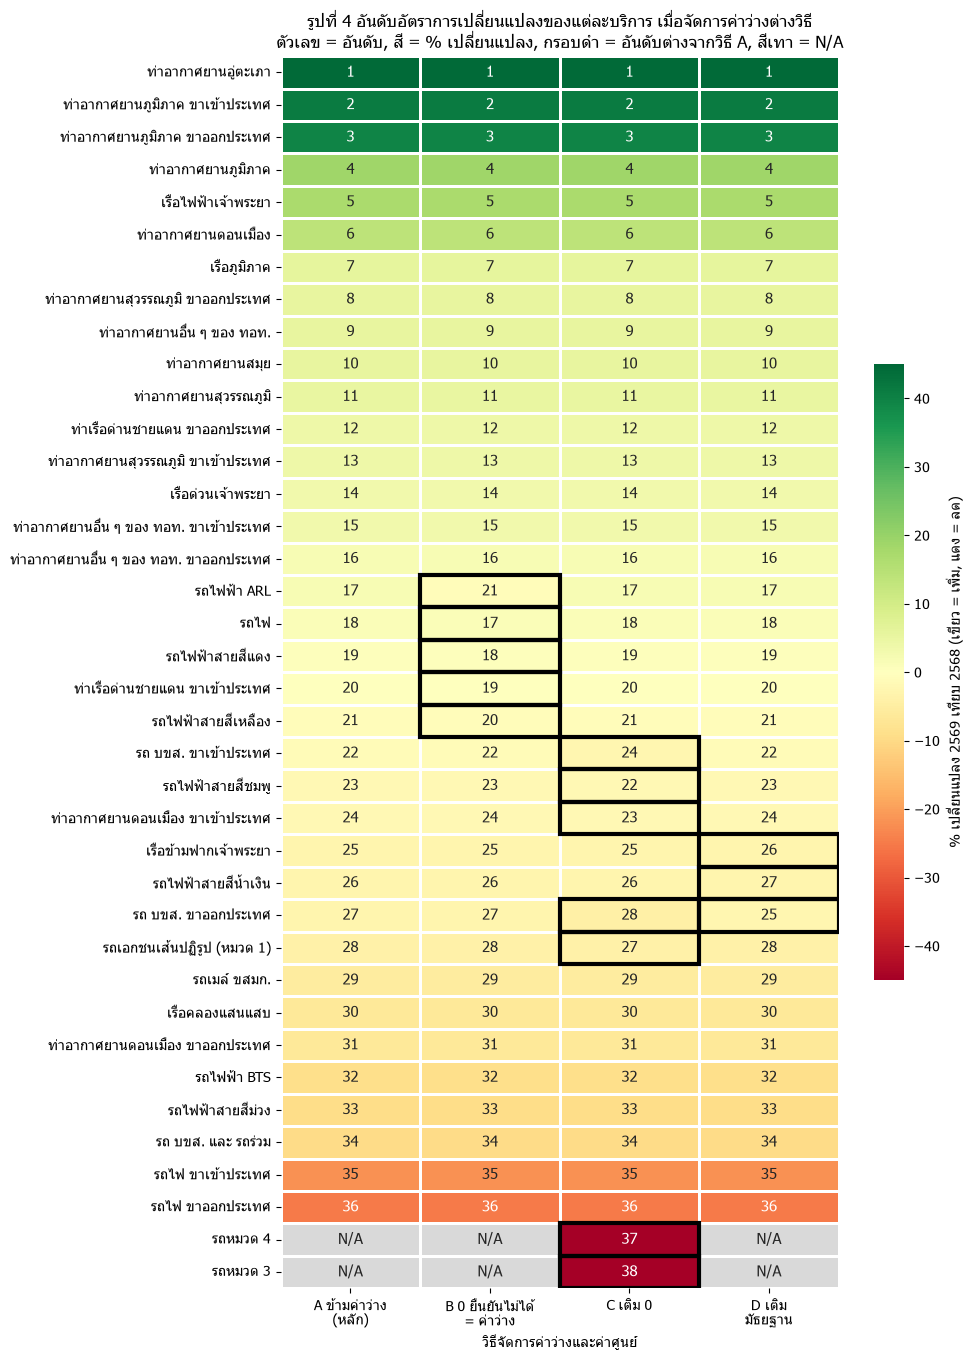

ช่องที่อันดับต่างจากวิธี A: 15 ช่อง
วิธี B: อันดับเปลี่ยน 5 บริการ | เลื่อนมากสุด 4 อันดับ
วิธี C: อันดับเปลี่ยน 5 บริการ | เลื่อนมากสุด 2 อันดับ
วิธี D: อันดับเปลี่ยน 3 บริการ | เลื่อนมากสุด 2 อันดับ
บริการที่ไม่มีอันดับในวิธี A: ['รถหมวด 4', 'รถหมวด 3']


In [13]:
# ===== รูปที่ 4 Rank Comparison Heatmap: บริการ × วิธีจัดการค่าว่าง (AIE314 บทที่ 7 หน้า 23–26) =====
# ใช้ rank_tab และ pct_tab จากเซลล์ก่อนหน้า (แถว = บริการ, คอลัมน์ = วิธี A–D)
# ตัวเลขในช่อง = อันดับ, สีในช่อง = % เปลี่ยนแปลง (เขียว = เพิ่ม, แดง = ลด)
# กรอบดำหนา = อันดับต่างจากวิธี A, สีเทา = คำนวณไม่ได้ (N/A)
order = rank_tab[["A", "B", "C", "D"]].sort_values(["A", "C"]).index   # เรียงตามอันดับวิธี A, N/A อยู่ท้าย
rank_sorted = rank_tab.loc[order, ["A", "B", "C", "D"]]
pct_sorted = pct_tab.loc[order, ["A", "B", "C", "D"]]

# ข้อความในช่อง: อันดับจริง ช่องที่ไม่มีอันดับแสดง "N/A" ไม่แทนด้วย 0
labels = rank_sorted.copy().astype(object)
for m in ["A", "B", "C", "D"]:
    labels[m] = rank_sorted[m].map(lambda v: "N/A" if pd.isna(v) else str(int(v)))

col_names = ["A ข้ามค่าว่าง\n(หลัก)", "B 0 ยืนยันไม่ได้\n= ค่าว่าง", "C เติม 0", "D เติม\nมัธยฐาน"]
plt.figure(figsize= (9, 16))
# ชั้นที่ 1: ระบายสีตาม % เปลี่ยนแปลง ค่าเกิน ±45% ใช้สีเข้มสุด (เช่น −100% ของวิธี C)
ax = sns.heatmap(pct_sorted, cmap= "RdYlGn", center= 0, vmin= -45, vmax= 45,
                 annot= labels, fmt= "", annot_kws= {"size": 11},
                 linewidths= 0.8, linecolor= "white",
                 cbar_kws= {"label": "% เปลี่ยนแปลง 2569 เทียบ 2568 (เขียว = เพิ่ม, แดง = ลด)", "shrink": 0.5})
# ชั้นที่ 2: ช่องที่คำนวณไม่ได้ ระบายสีเทา
sns.heatmap(pct_sorted.isna().astype(float), mask= pct_sorted.notna(), cmap= "Greys", vmin= 0, vmax= 4,
            annot= labels, fmt= "", annot_kws= {"size": 11}, cbar= False,
            linewidths= 0.8, linecolor= "white", ax= ax)
# ชั้นที่ 3: ตีกรอบดำหนาให้ช่องที่อันดับต่างจากวิธี A
n_box = 0
for i, svc in enumerate(order):
    for j, m in enumerate(["B", "C", "D"], start= 1):
        a, b = rank_sorted.loc[svc, "A"], rank_sorted.loc[svc, m]
        if pd.notna(b) and (pd.isna(a) or a != b):
            ax.add_patch(plt.Rectangle((j, i), 1, 1, fill= False, edgecolor= "black", linewidth= 3))
            n_box += 1

ax.set_xticklabels(col_names, rotation= 0)
plt.title("รูปที่ 4 อันดับอัตราการเปลี่ยนแปลงของแต่ละบริการ เมื่อจัดการค่าว่างต่างวิธี\n"
          "ตัวเลข = อันดับ, สี = % เปลี่ยนแปลง, กรอบดำ = อันดับต่างจากวิธี A, สีเทา = N/A")
plt.xlabel("วิธีจัดการค่าว่างและค่าศูนย์"); plt.ylabel("")
plt.savefig(FIG_DIR / "q2_fig4_rank_heatmap.png", dpi= 150, bbox_inches= "tight")
plt.show()

# ตรวจผล: จำนวนช่องที่มีกรอบ และจำนวนบริการที่อันดับเปลี่ยนในแต่ละวิธี
print("ช่องที่อันดับต่างจากวิธี A:", n_box, "ช่อง")
for m in ["B", "C", "D"]:
    d = (rank_sorted[m] - rank_sorted["A"]).abs()
    print(f"วิธี {m}: อันดับเปลี่ยน {(d > 0).sum()} บริการ | เลื่อนมากสุด {d.max():.0f} อันดับ")
print("บริการที่ไม่มีอันดับในวิธี A:", rank_sorted[rank_sorted["A"].isna()].index.tolist())

**ตีความรูปที่ 4:** อันดับ 1–16 และ 29–36 เหมือนกันทุกวิธี (ไม่มีกรอบดำ) อันดับที่ขยับมีแค่ช่วง 17–28 ซึ่งเป็นสีเหลืองอ่อนทั้งหมด เพราะ pct_change ในวิธี A ใกล้ 0 มาก (−3.9% ถึง +1.9%) ต่างกันไม่ถึง 1% ก็สลับอันดับได้ วิธี B ขยับมากสุดคือ ARL จาก 17 เป็น 21 รถหมวด 3/4 เป็น N/A ในวิธี A, B, D และได้อันดับ 37–38 (−100%, สีแดงเข้ม) เฉพาะวิธี C ซึ่งเกิดจากการเติม 0 ไม่ใช่การลดลงจริง

*หมายเหตุเครื่องมือ:* `pivot_table`, `set_xticklabels`, `vmin`/`vmax`, `mask` (heatmap สองชั้น), `cbar_kws`, `annot_kws`, `.map(lambda)`, `enumerate` และ `ax.add_patch(plt.Rectangle(...))` (กรอบดำ) ไม่อยู่ในเอกสารรายวิชา

## สรุปคำตอบ Q2

1. **ภาพรวม (รูปที่ 1):** ช่วง 1 ม.ค.–11 มี.ค. ปี 2569 ผู้ใช้บริการ 36 บริการลดลง 3.5% จากปี 2568 (3,194,280 → 3,082,495 คน/วัน) ในเมืองลด 4.5% ระหว่างจังหวัดทรงตัว (+0.5%) ระหว่างประเทศเพิ่ม 3.0%
2. **รายบริการ (รูปที่ 2):** เพิ่ม 20 ลด 16 บริการ เพิ่มมากสุดคือท่าอากาศยานภูมิภาคและอู่ตะเภา (+40% ขึ้นไป) ลดมากสุดคือรถไฟระหว่างประเทศ (−22% ถึง −25%) และรถไฟฟ้าสายสีม่วง/BTS (ประมาณ −9%)
3. **การจัดการค่าว่าง/ศูนย์ (รูปที่ 3):** ถ้าเติมค่าว่างด้วย 0 ข้อสรุปของกลุ่มระหว่างจังหวัดจะกลับทิศ (+0.53% เป็น −1.16%) และถ้าถือ 0 ที่ยังยืนยันไม่ได้เป็นค่าว่าง ARL จะเปลี่ยนจากเพิ่มเป็นลด วิธีอื่นอันดับเลื่อนไม่เกิน 4 อันดับ

**ข้อจำกัด:** ปี 2569 มีข้อมูลแค่ 70 วัน ผลไม่แทนทั้งปี / เทศกาล เช่น ตรุษจีน ตกคนละวันในสองปี (แต่อยู่ในช่วงทั้งคู่) / % ของบริการฐานเล็กแกว่งง่าย / ไม่รวมบริการหน่วยคันและ 3 บริการที่ไม่มีข้อมูล

## บันทึกผลลัพธ์ Q2
ตารางรายบริการ × 4 วิธีจัดการค่าว่าง/ศูนย์ method A = ผลหลัก (36 บริการ) ใช้สร้างรูปที่ 1–3

In [14]:
# ตารางผลรายบริการ × วิธี (method A = ผลหลัก)
q2_out = sens.rename(columns= {"avg_daily_x": "avg_2568", "avg_daily_y": "avg_2569"})
q2_out.to_csv("../outputs/q2_yoy_by_method.csv", index= False, encoding= "utf-8-sig")

# อ่านกลับมาตรวจ
back = pd.read_csv("../outputs/q2_yoy_by_method.csv")
print("บันทึกแล้ว: ", back.shape)
display(back.groupby("method").size())

บันทึกแล้ว:  (146, 7)


method
A    36
B    36
C    38
D    36
dtype: int64